In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from astropy.stats import sigma_clip
from photutils.aperture import CircularAnnulus, CircularAperture
from scipy import ndimage

warnings.filterwarnings("ignore")
DATA, RES, FIG = Path(".."), Path("results"), Path("figures")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})

with fits.open(DATA / "mosaic.fits") as hdul:
    data = hdul[0].data.astype(float); header = hdul[0].header
mask = fits.getdata(RES / "mask.fits").astype(bool)
segm = fits.getdata(RES / "segmentation.fits").astype(np.int64)
cat = Table.read(RES / "catalogue.ecsv")
GAIN, ZP_LAB, EXPTIME = float(header.get("GAIN", 3.1)), float(header["MAGZPT"]), float(header["EXPTIME"])

In [2]:
R_AP = 6.0                     # aperture radius (px)
R_IN, R_OUT = 15.0, 25.0       # sky ring (px)
R_OUT_STEP, R_OUT_MAX, MIN_SKY_PIX = 10.0, 55.0, 60   # widen the ring if it has < 60 usable pixels
SEG_GROW = 8                   # pixels of other sources (grown by 8 px) are not used for the sky
NEIGHBOUR_FLAG_FRAC = 0.10
FLAG_MASKED, FLAG_NEIGHBOUR, FLAG_SKY, FLAG_NONPOSITIVE, FLAG_EDGE = 1, 2, 4, 8, 16
COG_RADII, COG_R_TOTAL = np.arange(1.0, 26.0, 1.0), 20.0
N_EMPTY = 3000

# pixels that may NOT be used to measure the sky
not_sky = mask | ndimage.binary_dilation(segm > 0, iterations=SEG_GROW)

In [3]:
def local_sky(x, y, r_in=R_IN, r_out=R_OUT, image=None, not_sky_map=None):
    """Median and std of the sky in a ring around (x, y); widen the ring if too few clean pixels."""
    image = data if image is None else image
    not_sky_map = not_sky if not_sky_map is None else not_sky_map
    widened = False
    while True:
        ann = CircularAnnulus((x, y), r_in, r_out).to_mask(method="center")
        vals = ann.cutout(image, fill_value=np.nan)
        bad = ann.cutout(not_sky_map.astype(float), fill_value=1.0) > 0
        use = (ann.data > 0) & ~bad & np.isfinite(vals)
        n = int(use.sum())
        if n >= MIN_SKY_PIX or r_out >= R_OUT_MAX:
            break
        r_out += R_OUT_STEP; widened = True
    if n < 5:
        return np.nan, np.nan, n, True
    clipped = sigma_clip(vals[use], sigma=3.0, maxiters=10, masked=False)
    return float(np.median(clipped)), float(np.std(clipped)), int(clipped.size), widened or n < MIN_SKY_PIX


def aperture_sum(x, y, r, sky, own_label, image=None, mask_map=None, segm_map=None):
    """Sky-subtracted flux in a circle; masked / neighbouring pixels are replaced by the sky."""
    image = data if image is None else image
    mask_map = mask if mask_map is None else mask_map
    segm_map = segm if segm_map is None else segm_map
    ap = CircularAperture((x, y), r).to_mask(method="exact")
    w = ap.data
    vals = ap.cutout(image, fill_value=np.nan)
    msk = ap.cutout(mask_map.astype(float), fill_value=1.0) > 0
    seg = ap.cutout(segm_map, fill_value=0)
    off_image = bool(np.any(~np.isfinite(vals) & (w > 0)))
    neighbour = (seg > 0) & (seg != own_label)
    vals = np.where(np.isfinite(vals), vals, sky)
    vals = np.where(msk | neighbour, sky, vals)
    frac_mask = float((w * msk).sum() / w.sum())
    frac_nb = float((w * (neighbour & ~msk)).sum() / w.sum())
    return float((w * (vals - sky)).sum()), float(w.sum()), frac_mask, frac_nb, off_image


def flux_error(flux, area, sky_std, n_sky, gain, corr):
    poisson = max(flux, 0.0) / gain                    # source photon noise (in counts^2)
    sky_var = corr ** 2 * area * sky_std ** 2          # sky noise inside the aperture
    sky_est = corr ** 2 * area ** 2 * sky_std ** 2 / max(n_sky, 1)   # uncertainty of the sky level itself
    return float(np.sqrt(poisson + sky_var + sky_est))

In [4]:
rng = np.random.default_rng(0)
ny, nx = data.shape
clear = ~ndimage.binary_dilation(not_sky, iterations=int(np.ceil(R_AP)) + 1)
sums, expected = [], []
tries = 0
while len(sums) < N_EMPTY and tries < 50 * N_EMPTY:
    tries += 1
    x, y = rng.uniform(R_OUT, nx - R_OUT), rng.uniform(R_OUT, ny - R_OUT)
    if not clear[int(y), int(x)]:
        continue
    s, s_std, n, bad = local_sky(x, y)
    if bad or not np.isfinite(s):
        continue
    f, area, _, _, _ = aperture_sum(x, y, R_AP, s, -1)
    sums.append(f); expected.append(s_std * np.sqrt(area))
sums = np.array(sums)
measured = float(1.4826 * np.median(np.abs(sums - np.median(sums))))
expected = float(np.median(expected))
CORR = measured / expected
print(f"empty apertures: scatter {measured:.1f} counts vs {expected:.1f} expected -> correction factor {CORR:.2f}")

empty apertures: scatter 163.6 counts vs 87.1 expected -> correction factor 1.88


In [5]:
rows = []
for x, y, lab in zip(np.asarray(cat["x"]), np.asarray(cat["y"]), np.asarray(cat["label"])):
    s, s_std, n, sky_bad = local_sky(x, y)
    f, area, fm, fn, off = aperture_sum(x, y, R_AP, s, lab)
    err = flux_error(f, area, s_std, n, GAIN, CORR) if np.isfinite(s_std) else np.nan
    flag = (FLAG_MASKED * (fm > 0) | FLAG_NEIGHBOUR * (fn > NEIGHBOUR_FLAG_FRAC) | FLAG_SKY * sky_bad
            | FLAG_NONPOSITIVE * (not f > 0) | FLAG_EDGE * off)
    rows.append((lab, x, y, f, err, s, s_std, n, area, fm, fn, int(flag)))
phot = Table(rows=rows, names=["label", "x", "y", "ap_flux", "ap_flux_err", "sky", "sky_std", "n_sky", "ap_area",
                               "frac_masked", "frac_neighbour", "flag"])
print(f"{len(phot)} sources measured; {np.sum(phot['flag'] == 0)} have no warning flags")

5917 sources measured; 5452 have no warning flags


In [6]:
ok = (cat["snr"] > 80) & (cat["ellipticity"] < 0.1) & (cat["peak"] < 20000) & ~np.asarray(cat["near_mask"], bool)
cand = cat[ok]
xs, ys = np.asarray(cat["x"]), np.asarray(cat["y"])
keep = [i for i, (x, y) in enumerate(zip(cand["x"], cand["y"])) if np.sum(np.hypot(xs - x, ys - y) < 30) == 1]
cog_stars = cand[keep]; cog_stars.sort("fwhm"); cog_stars = cog_stars[:40]
curves, frac = [], []
for x, y, lab in zip(cog_stars["x"], cog_stars["y"], cog_stars["label"]):
    s, _, _, bad = local_sky(x, y, r_in=COG_R_TOTAL + 5, r_out=COG_R_TOTAL + 20)
    if bad or not np.isfinite(s):
        continue
    fl = np.array([aperture_sum(x, y, r, s, lab)[0] for r in COG_RADII])
    f_tot = aperture_sum(x, y, COG_R_TOTAL, s, lab)[0]
    f_std = aperture_sum(x, y, R_AP, local_sky(x, y)[0], lab)[0]
    if f_tot > 0:
        curves.append(fl / f_tot); frac.append(f_std / f_tot)
curves = np.array(curves)
AP_FRAC = float(np.median(frac)); AP_CORR_MAG = -2.5 * np.log10(AP_FRAC)
print(f"{len(curves)} stars: {100 * AP_FRAC:.1f}% of a star's light is inside r = {R_AP:g} px "
      f"-> aperture correction {AP_CORR_MAG:.3f} mag")

35 stars: 73.3% of a star's light is inside r = 6 px -> aperture correction 0.337 mag


In [7]:
with np.errstate(divide="ignore", invalid="ignore"):
    phot["mag_ap_lab"] = np.where(phot["ap_flux"] > 0, ZP_LAB - 2.5 * np.log10(phot["ap_flux"]), np.nan)
    phot["mag_ap_err"] = np.where(phot["ap_flux"] > 0, 2.5 / np.log(10) * phot["ap_flux_err"] / phot["ap_flux"], np.nan)
phot["snr_ap"] = phot["ap_flux"] / phot["ap_flux_err"]
phot.meta.update({"R_AP": R_AP, "CORR_FACTOR": CORR, "AP_FRAC": AP_FRAC, "AP_CORR_MAG": AP_CORR_MAG})
phot.write(RES / "photometry.ecsv", overwrite=True)
json.dump({"corr_factor": CORR, "ap_frac": AP_FRAC, "ap_corr_mag": AP_CORR_MAG, "n_cog_stars": len(curves),
           "n_flag0": int(np.sum(phot["flag"] == 0))}, open(RES / "photometry_summary.json", "w"), indent=1)

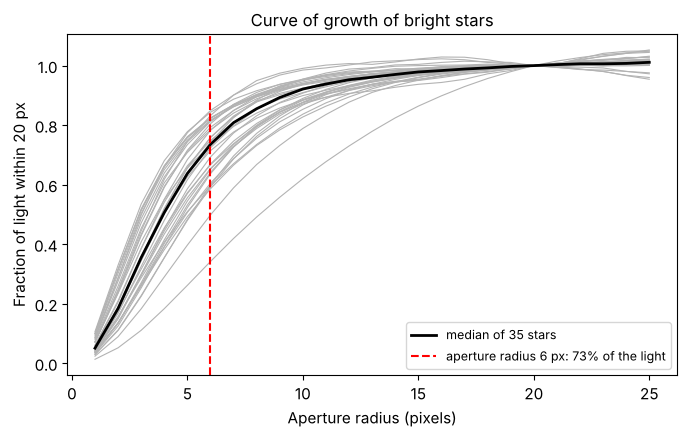

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c in curves:
    ax.plot(COG_RADII, c, color="0.7", lw=0.8)
ax.plot(COG_RADII, np.median(curves, axis=0), "k", lw=2, label=f"median of {len(curves)} stars")
ax.axvline(R_AP, color="r", ls="--", label=f"aperture radius {R_AP:g} px: {100 * AP_FRAC:.0f}% of the light")
ax.set_xlabel("Aperture radius (pixels)"); ax.set_ylabel(f"Fraction of light within {COG_R_TOTAL:g} px")
ax.set_title("Curve of growth of bright stars"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "03_curve_of_growth.png"); plt.show()

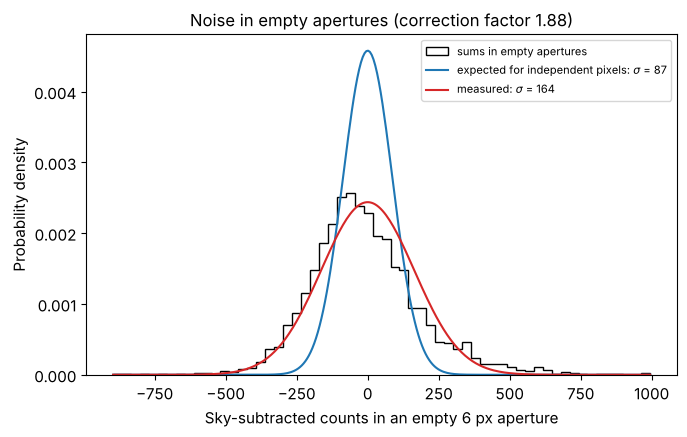

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(sums, bins=60, density=True, histtype="step", color="k", label="sums in empty apertures")
g = np.linspace(sums.min(), sums.max(), 300)
for s, lab, c in ((expected, "expected for independent pixels", "C0"), (measured, "measured", "C3")):
    ax.plot(g, np.exp(-g ** 2 / (2 * s ** 2)) / (s * np.sqrt(2 * np.pi)), c, label=fr"{lab}: $\sigma$ = {s:.0f}")
ax.set_xlabel("Sky-subtracted counts in an empty 6 px aperture"); ax.set_ylabel("Probability density")
ax.set_title(f"Noise in empty apertures (correction factor {CORR:.2f})"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_empty_apertures.png"); plt.show()

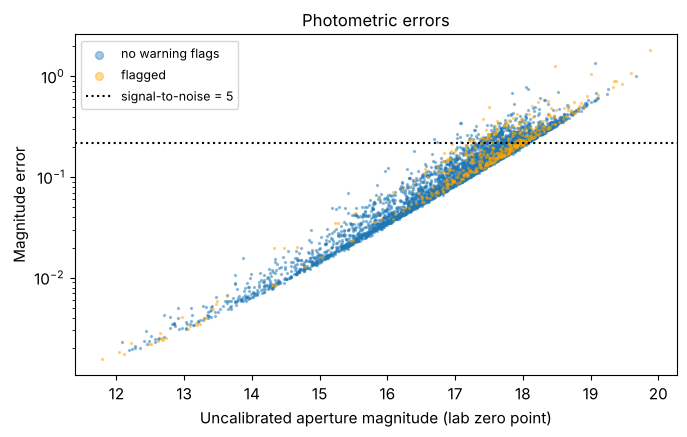

In [10]:
good = phot["flag"] == 0
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(phot["mag_ap_lab"][good], phot["mag_ap_err"][good], s=2, alpha=0.4, label="no warning flags")
ax.scatter(phot["mag_ap_lab"][~good], phot["mag_ap_err"][~good], s=2, alpha=0.4, color="orange", label="flagged")
ax.axhline(2.5 / np.log(10) / 5, color="k", ls=":", label="signal-to-noise = 5")
ax.set_yscale("log"); ax.set_xlabel("Uncalibrated aperture magnitude (lab zero point)")
ax.set_ylabel("Magnitude error"); ax.set_title("Photometric errors"); ax.legend(markerscale=4)
fig.tight_layout(); fig.savefig(FIG / "03_photometric_errors.png"); plt.show()